In [1]:
from langgraph.graph import START,END,StateGraph,MessagesState
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os

In [9]:
my_secret_key = os.getenv("GROQ_API_KEY")
load_dotenv()
llm = ChatGroq(
    model="openai/gpt-oss-20b",  # Current standard for high-accuracy reasoning workflows
    api_key=my_secret_key,
    temperature=0.3
)

In [3]:
def call_mode(state:MessagesState):
    response = llm.invoke(state['messages'])
    return {'messages':[response]}

In [4]:
graph = StateGraph(MessagesState)

#add nodes 
graph.add_node('call_mode',call_mode)
graph.add_edge(START,'call_mode')
graph.add_edge('call_mode',END)



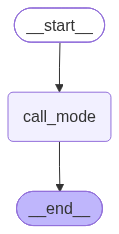

In [6]:
workflow = graph.compile()
workflow

In [7]:
workflow.invoke({"messages": [{"role": "user", "content": "Hi! My name is Nitish."}]})

{'messages': [HumanMessage(content='Hi! My name is Nitish.', additional_kwargs={}, response_metadata={}, id='e63a307b-f841-4529-b108-27774be900a7'),
  AIMessage(content='Hello Nitish! 👋 How can I assist you today?', additional_kwargs={'reasoning_content': 'We have a conversation. The user says "Hi! My name is Nitish." We should respond politely, asking how we can help. There\'s no policy violation. Just a friendly greeting.'}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 79, 'total_tokens': 140, 'completion_time': 0.066423433, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.005335698, 'prompt_tokens_details': None, 'queue_time': 0.368211739, 'total_time': 0.071759131}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ece3-9017-71e7-bf76-bdbca3cf72c6-0', tool_calls=[], invalid_tool_calls=[], u

In [8]:
workflow.invoke({"messages": [{"role": "user", "content": "What is my name?"}]})

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='7a848598-73f2-495d-9ca0-9c34ddf1da54'),
  AIMessage(content='I’m not sure what your name is—could you let me know?', additional_kwargs={'reasoning_content': 'We need to answer "What is my name?" The user hasn\'t provided their name. We can\'t guess. The policy says we should respond truthfully; if we don\'t know, we should say we don\'t know. So answer: I don\'t know your name.'}, response_metadata={'token_usage': {'completion_tokens': 76, 'prompt_tokens': 76, 'total_tokens': 152, 'completion_time': 0.077791606, 'completion_tokens_details': {'reasoning_tokens': 52}, 'prompt_time': 0.003683871, 'prompt_tokens_details': None, 'queue_time': 0.156193254, 'total_time': 0.081475477}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ece4-5491-7194-b2e4-

In [10]:
def call_model(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

In [11]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")
builder.add_edge('call_model',END)

In [13]:
#checkpointer generally used to save all our previous conversions 
from langgraph.checkpoint.memory import InMemorySaver
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

In [14]:
config = {"configurable": {"thread_id": "thread-1"}}
config2 = {"configurable": {"thread_id": "thread-2"}}

In [15]:
graph.invoke({"messages": [{"role": "user", "content": "Hi! My name is Nitish."}]}, config)

{'messages': [HumanMessage(content='Hi! My name is Nitish.', additional_kwargs={}, response_metadata={}, id='1c926392-d8f4-4740-996e-a6f44982f9c0'),
  AIMessage(content='Hello Nitish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi! My name is Nitish." We should greet them. Probably ask how can I help.'}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 79, 'total_tokens': 131, 'completion_time': 0.054141546, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.003869405, 'prompt_tokens_details': None, 'queue_time': 0.258307224, 'total_time': 0.058010951}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e2cb7a84ec', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ece9-6e8e-7127-96d7-69aa6458ab47-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 52, 'total_

In [17]:
graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config2)

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='8dedd32b-b80c-4141-9617-f7584f27cbe2'),
  AIMessage(content='I’m not sure what your name is—could you let me know?', additional_kwargs={'reasoning_content': 'The user asks "What is my name?" There\'s no prior context. The user hasn\'t provided their name. According to policy, we should not guess. We can respond that we don\'t know. We can ask them to tell us. Also we can say we don\'t have that info. So respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 76, 'total_tokens': 161, 'completion_time': 0.092973626, 'completion_tokens_details': {'reasoning_tokens': 61}, 'prompt_time': 0.006818518, 'prompt_tokens_details': None, 'queue_time': 0.37878664, 'total_time': 0.099792144}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'g

In [18]:
snap = graph.get_state(config)
vals = snap.values
for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content)

- HumanMessage : Hi! My name is Nitish.
- AIMessage : Hello Nitish! 👋 How can I help you today?
